# Visualize YOLOv3 Bounding Boxes — CrowdPose

Loads the generated `boxes_crowdpose_test.json` and shows predicted person boxes on sampled images.
Also overlays ground-truth person annotations from `crowdpose_test.json` for comparison.

In [ ]:
import json
import random
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Paths
ANN_DIR  = Path("data/crowdpose/annotations")
IMG_ROOT = Path("data/crowdpose/images")
SPLIT    = "test"
SEED     = 42

# Subset: set to an integer to analyse only that many images (same subset everywhere).
# Set to None to use all images.
SUBSET_SIZE = None

N_IMAGES = 12  # images shown in the visualization grid (must be <= SUBSET_SIZE)

In [12]:
# ── Load generated boxes ────────────────────────────────────────────────────
boxes_path = ANN_DIR / f"boxes_crowdpose_{SPLIT}.json"
with open(boxes_path) as fh:
    generated = json.load(fh)

gen_by_img: dict[int, list[dict]] = {}
for det in generated:
    gen_by_img.setdefault(det["image_id"], []).append(det)

print(f"Loaded {len(generated)} detections for {len(gen_by_img)} images")

Loaded 56898 detections for 8000 images


In [13]:
# ── Load ground-truth annotations ───────────────────────────────────────────
gt_path = ANN_DIR / f"crowdpose_{SPLIT}.json"
with open(gt_path) as fh:
    gt_data = json.load(fh)

image_meta = {img["id"]: img for img in gt_data["images"]}

# Build GT person boxes from crowdpose annotations
# Each annotation has a "bbox" [x, y, w, h] in pixel space
gt_by_img: dict[int, list[list[float]]] = {}
for ann in gt_data["annotations"]:
    gt_by_img.setdefault(ann["image_id"], []).append(ann["bbox"])

print(f"GT: {len(gt_data['images'])} images, {len(gt_data['annotations'])} person annotations")

GT: 8000 images, 35283 person annotations


In [14]:
# ── Load reference file (det_for_crowd_test_0.1_0.5.json) ───────────────────
ref_path = ANN_DIR / "det_for_crowd_test_0.1_0.5.json"
ref_by_img: dict[int, list[dict]] = {}
if ref_path.exists():
    with open(ref_path) as fh:
        reference = json.load(fh)
    for det in reference:
        ref_by_img.setdefault(det["image_id"], []).append(det)
    print(f"Reference: {len(reference)} detections for {len(ref_by_img)} images")
else:
    print("Reference file not found — skipping reference overlay")

Reference: 65004 detections for 8000 images


In [15]:
# ── Build analysis subset (used by all cells below) ─────────────────────────
random.seed(SEED)
all_image_ids = list(image_meta.keys())

if SUBSET_SIZE is not None and SUBSET_SIZE < len(all_image_ids):
    subset_ids = random.sample(all_image_ids, SUBSET_SIZE)
else:
    subset_ids = all_image_ids

print(f"Subset: {len(subset_ids)} / {len(all_image_ids)} images  (SUBSET_SIZE={SUBSET_SIZE})")

Subset: 200 / 8000 images  (SUBSET_SIZE=200)


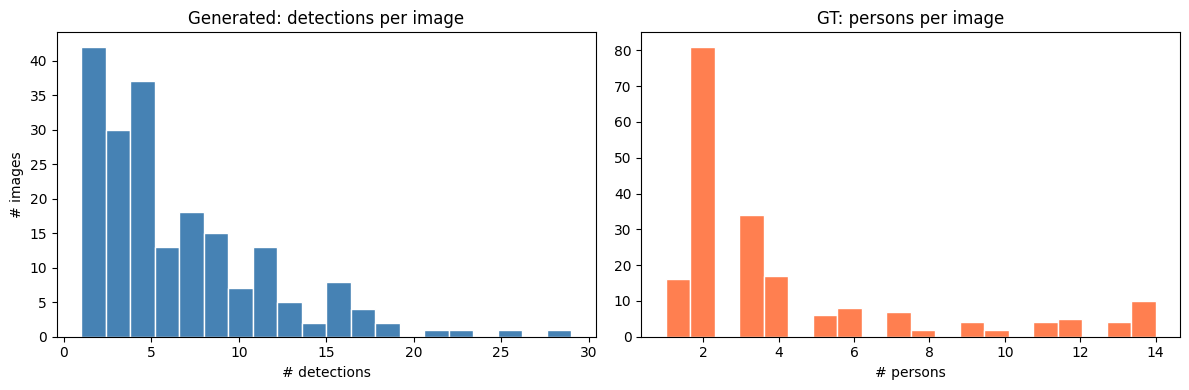

Generated — mean: 6.47, max: 29
GT        — mean: 4.21,  max: 14


In [16]:
# ── Detection statistics ─────────────────────────────────────────────────────
det_counts = [len(gen_by_img.get(img_id, [])) for img_id in subset_ids]
gt_counts  = [len(gt_by_img.get(img_id,  [])) for img_id in subset_ids]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(det_counts, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Generated: detections per image")
axes[0].set_xlabel("# detections")
axes[0].set_ylabel("# images")

axes[1].hist(gt_counts, bins=20, color="coral", edgecolor="white")
axes[1].set_title("GT: persons per image")
axes[1].set_xlabel("# persons")

plt.tight_layout()
plt.show()

print(f"Generated — mean: {np.mean(det_counts):.2f}, max: {max(det_counts)}")
print(f"GT        — mean: {np.mean(gt_counts):.2f},  max: {max(gt_counts)}")

In [17]:
# ── Helper: draw boxes on an axis ────────────────────────────────────────────
def draw_boxes(ax, boxes_xywh, scores=None, color="lime", linewidth=2, label=None):
    """Draw COCO [x, y, w, h] boxes on a matplotlib axis."""
    for i, (x, y, w, h) in enumerate(boxes_xywh):
        rect = mpatches.Rectangle(
            (x, y), w, h,
            linewidth=linewidth, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        if scores is not None:
            ax.text(x, y - 4, f"{scores[i]:.2f}",
                    color=color, fontsize=7, fontweight="bold")

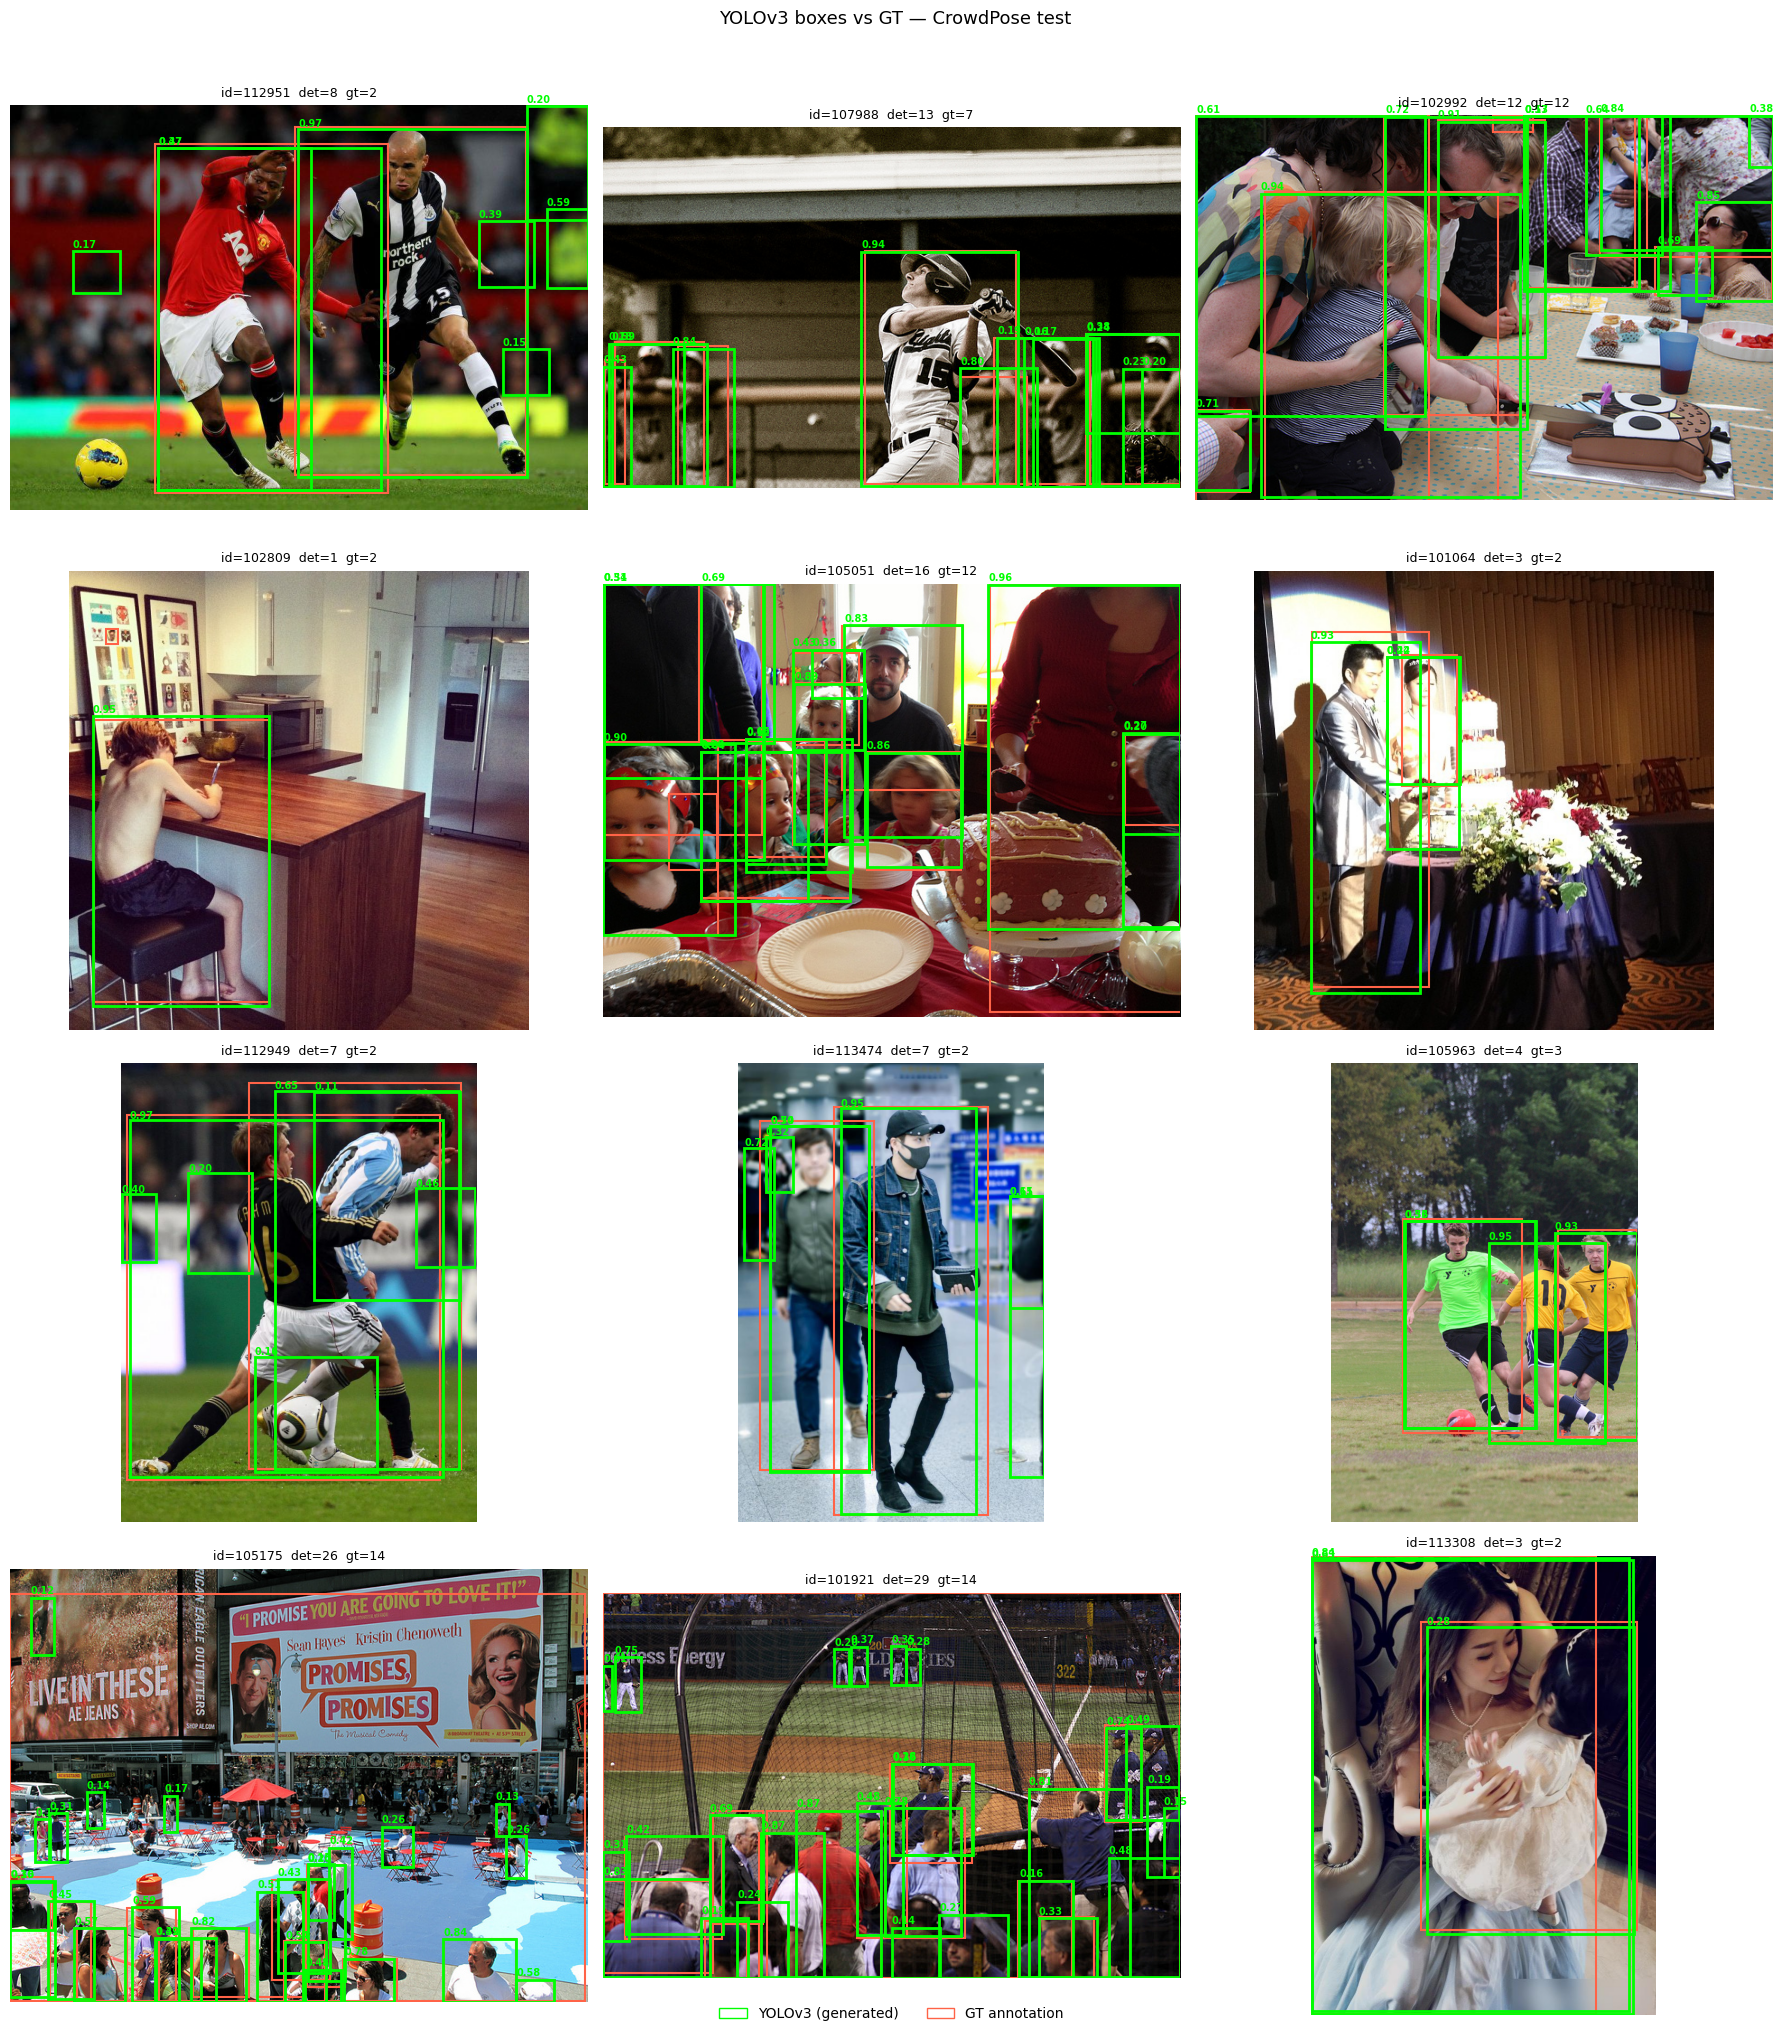

In [18]:
# ── Sample images and visualize ──────────────────────────────────────────────
detected_in_subset = [img_id for img_id in subset_ids if img_id in gen_by_img]
# random.seed already set above; reseed for reproducible visualization pick
random.seed(SEED + 1)
sample_ids = random.sample(detected_in_subset, min(N_IMAGES, len(detected_in_subset)))

cols = 3
rows = (len(sample_ids) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 6, rows * 5))
axes = axes.flatten()

for ax, img_id in zip(axes, sample_ids):
    meta  = image_meta[img_id]
    image = Image.open(IMG_ROOT / meta["file_name"]).convert("RGB")
    ax.imshow(image)

    # GT boxes (red)
    if img_id in gt_by_img:
        draw_boxes(ax, gt_by_img[img_id], color="tomato", linewidth=1.5)

    # Generated boxes (green) with scores
    if img_id in gen_by_img:
        dets   = gen_by_img[img_id]
        bboxes = [d["bbox"] for d in dets]
        scores = [d["score"] for d in dets]
        draw_boxes(ax, bboxes, scores=scores, color="lime", linewidth=2)

    n_det = len(gen_by_img.get(img_id, []))
    n_gt  = len(gt_by_img.get(img_id,  []))
    ax.set_title(f"id={img_id}  det={n_det}  gt={n_gt}", fontsize=9)
    ax.axis("off")

for ax in axes[len(sample_ids):]:
    ax.axis("off")

legend_patches = [
    mpatches.Patch(edgecolor="lime",   facecolor="none", label="YOLOv3 (generated)"),
    mpatches.Patch(edgecolor="tomato", facecolor="none", label="GT annotation"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=2, fontsize=10, frameon=False)
plt.suptitle(f"YOLOv3 boxes vs GT — CrowdPose {SPLIT}", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

IoU match rates (200 images, per reference box):
  IoU > 0.30 :  1107 / 1458 = 75.9%
  IoU > 0.50 :  1028 / 1458 = 70.5%
  IoU > 0.75 :   768 / 1458 = 52.7%
  IoU > 0.90 :   188 / 1458 = 12.9%


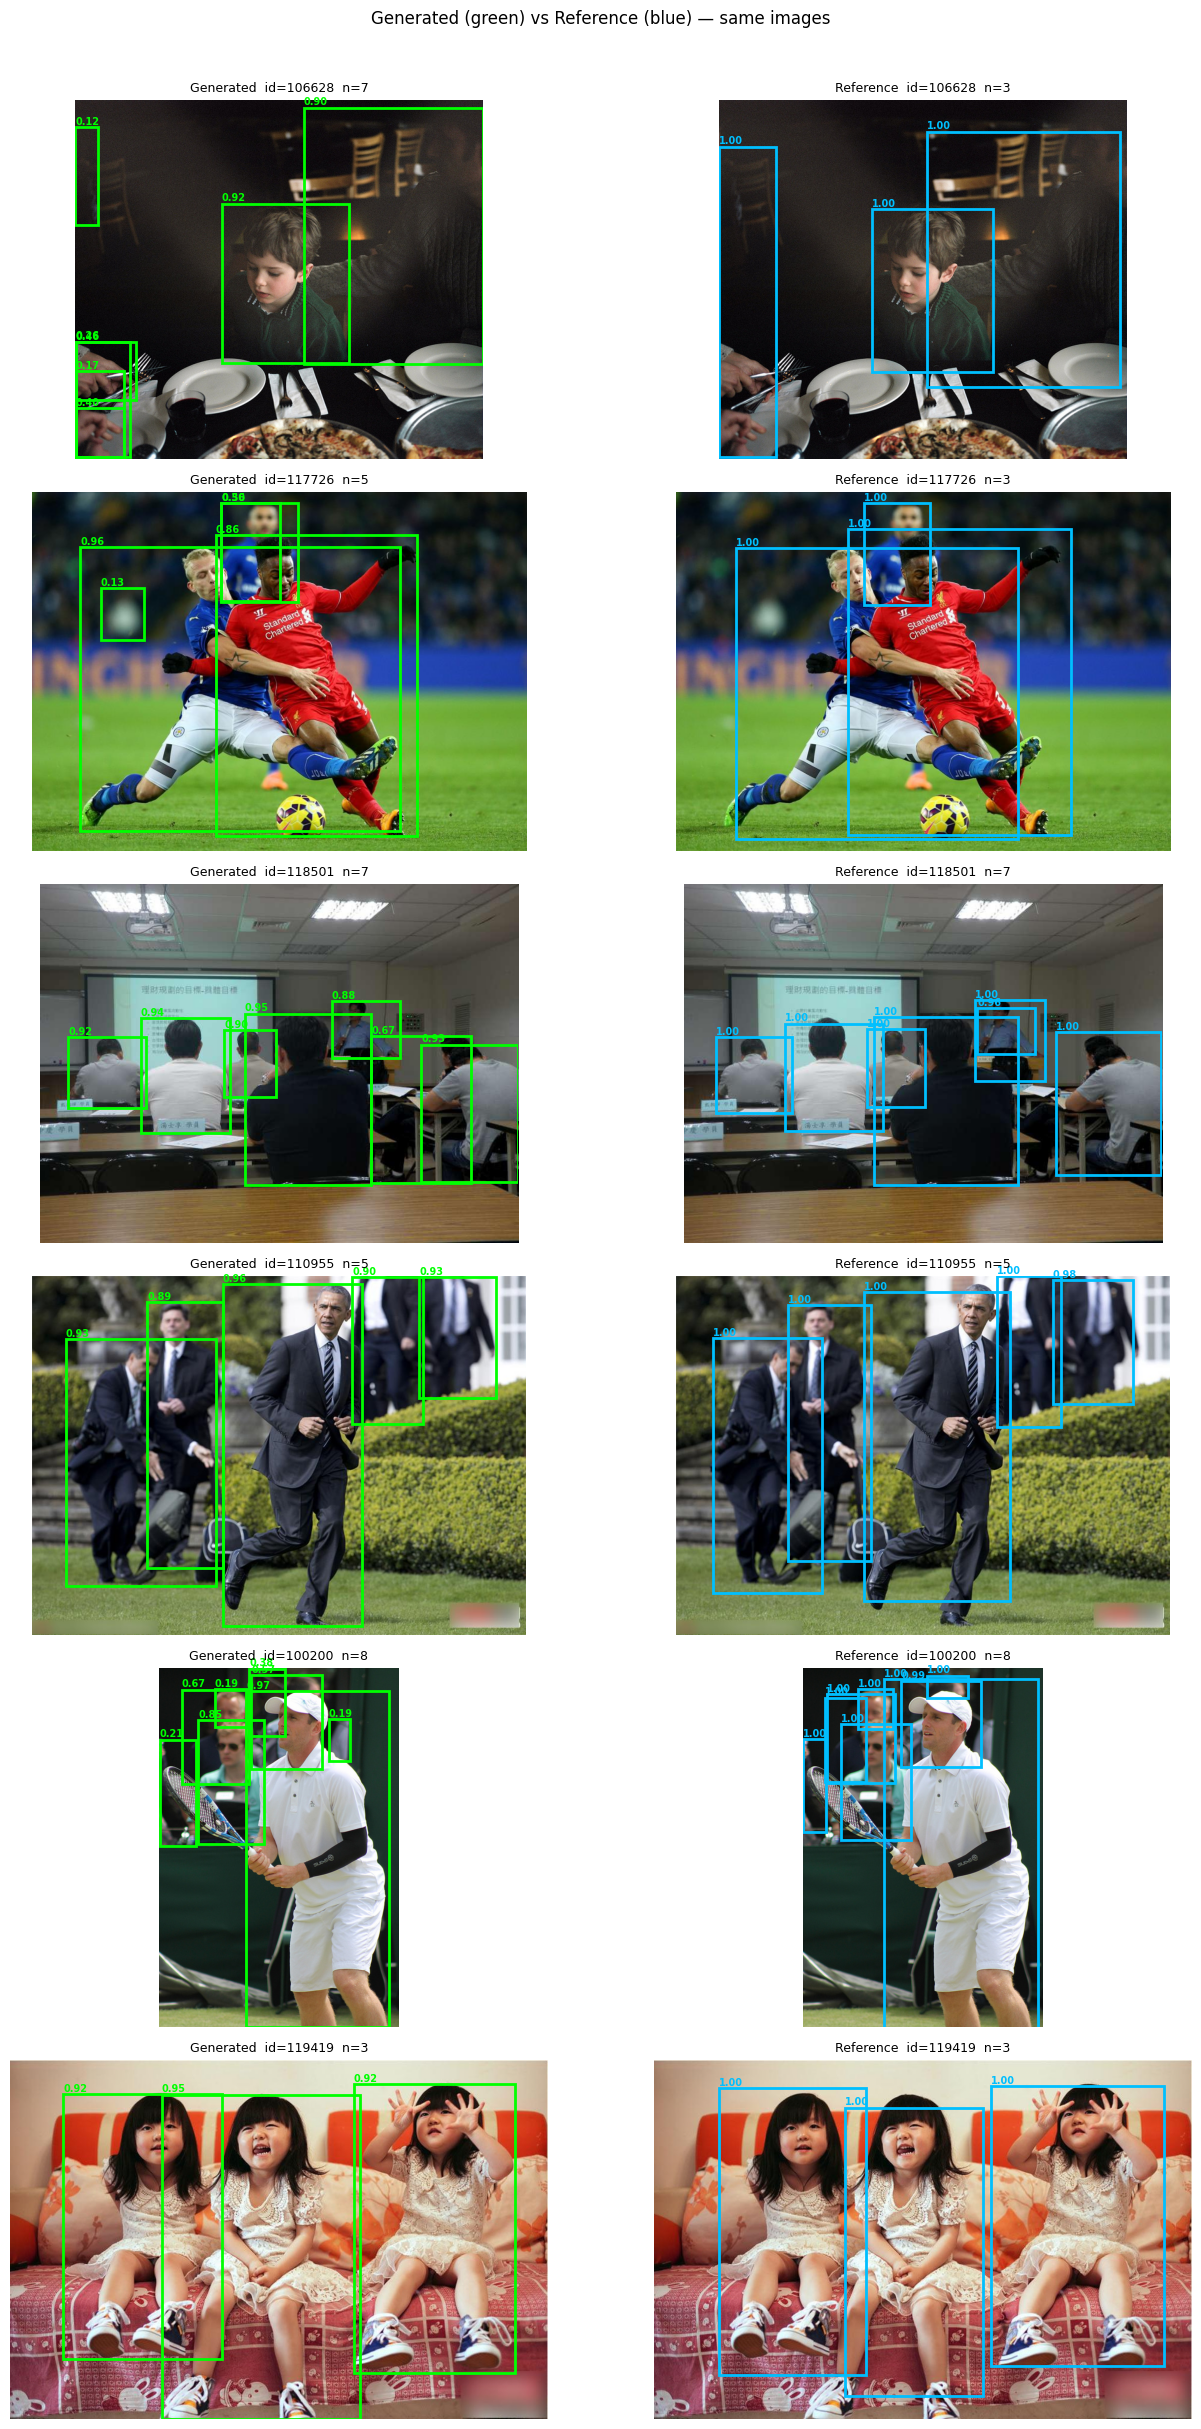

In [19]:
# ── Compare generated vs reference (det_for_crowd_test_0.1_0.5.json) ─────────
if ref_by_img:
    # Use the same subset_ids so verification and visualization cover identical images
    common_in_subset = [
        img_id for img_id in subset_ids
        if img_id in gen_by_img and img_id in ref_by_img
    ]

    # ── IoU match-rate table over the full subset ────────────────────────────
    def box_iou(a, b):
        ax1, ay1, aw, ah = a;  bx1, by1, bw, bh = b
        ax2, ay2 = ax1 + aw, ay1 + ah;  bx2, by2 = bx1 + bw, by1 + bh
        inter = max(0, min(ax2,bx2)-max(ax1,bx1)) * max(0, min(ay2,by2)-max(ay1,by1))
        union = aw*ah + bw*bh - inter
        return inter / union if union > 0 else 0.0

    thresholds = [0.3, 0.5, 0.75, 0.9]
    counts     = {t: 0 for t in thresholds}
    total_ref  = 0

    for img_id in common_in_subset:
        ref_boxes = [d["bbox"] for d in ref_by_img[img_id]]
        gen_boxes = [d["bbox"] for d in gen_by_img[img_id]]
        total_ref += len(ref_boxes)
        for rb in ref_boxes:
            best = max((box_iou(rb, gb) for gb in gen_boxes), default=0.0)
            for t in thresholds:
                if best > t:
                    counts[t] += 1

    print(f"IoU match rates ({len(common_in_subset)} images, per reference box):")
    for t in thresholds:
        rate = counts[t] / total_ref if total_ref else 0.0
        print(f"  IoU > {t:.2f} : {counts[t]:5d} / {total_ref} = {rate:.1%}")

    # ── Side-by-side image comparison ───────────────────────────────────────
    random.seed(SEED + 2)
    sample_ids_cmp = random.sample(common_in_subset, min(6, len(common_in_subset)))

    fig, axes = plt.subplots(len(sample_ids_cmp), 2,
                             figsize=(14, len(sample_ids_cmp) * 4))
    if len(sample_ids_cmp) == 1:
        axes = axes[np.newaxis, :]

    for row, img_id in enumerate(sample_ids_cmp):
        meta  = image_meta[img_id]
        image = Image.open(IMG_ROOT / meta["file_name"]).convert("RGB")

        axes[row, 0].imshow(image)
        if img_id in gen_by_img:
            dets   = gen_by_img[img_id]
            draw_boxes(axes[row, 0], [d["bbox"] for d in dets],
                       scores=[d["score"] for d in dets], color="lime")
        axes[row, 0].set_title(
            f"Generated  id={img_id}  n={len(gen_by_img.get(img_id, []))}",
            fontsize=9
        )
        axes[row, 0].axis("off")

        axes[row, 1].imshow(image)
        if img_id in ref_by_img:
            rdets = ref_by_img[img_id]
            draw_boxes(axes[row, 1], [d["bbox"] for d in rdets],
                       scores=[d["score"] for d in rdets], color="deepskyblue")
        axes[row, 1].set_title(
            f"Reference  id={img_id}  n={len(ref_by_img.get(img_id, []))}",
            fontsize=9
        )
        axes[row, 1].axis("off")

    plt.suptitle(
        "Generated (green) vs Reference (blue) — same images",
        fontsize=12, y=1.01
    )
    plt.tight_layout()
    plt.show()
else:
    print("Reference file not loaded; skipping side-by-side comparison.")